In [1]:
import duckdb

con = duckdb.connect()

# Schema check
con.sql("""
    DESCRIBE SELECT * FROM read_parquet(
    '/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet')
""").show()

# Row count, date range, unique sensor/road ids
con.sql("""
    SELECT MIN(DATETIME) AS start, MAX(DATETIME) AS end, COUNT(*) AS n_rows,
           COUNT(DISTINCT sensor_id) AS n_sensors
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet')
""").show()

con.sql("""
    SELECT ELEMENT_TYPE, COUNT(*) AS n_rows, COUNT(DISTINCT SENSOR_ID) AS n_sensors
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet')
    GROUP BY ELEMENT_TYPE
    ORDER BY n_rows DESC
""").show()

# ERROR_FLAG meaning and frequency — relevant for gap/quality handling
con.sql("""SELECT ERROR_FLAG, COUNT(*) FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet')
           GROUP BY ERROR_FLAG""").show()

# how many distinct sensors per ELEMENT_TYPE, and intensity range sanity check
con.sql("""SELECT ELEMENT_TYPE, AVG(TRAFFIC_INTENSITY), MIN(TRAFFIC_INTENSITY), MAX(TRAFFIC_INTENSITY)
           FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet') GROUP BY ELEMENT_TYPE""").show()


┌──────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │ column_type │  null   │   key   │ default │  extra  │
│           varchar            │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ SENSOR_ID                    │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ DATETIME                     │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ ELEMENT_TYPE                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ TRAFFIC_INTENSITY            │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ OCCUPANCY                    │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ LOAD                         │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ AVERAGE_SPEED                │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ ERROR_FLAG                   │ VARCHAR   

In [2]:

# Find the outlier rows
con.sql("""
    SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY, OCCUPANCY, AVERAGE_SPEED, ERROR_FLAG
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet')
    WHERE ELEMENT_TYPE = 'URB' AND TRAFFIC_INTENSITY > 5000
    ORDER BY TRAFFIC_INTENSITY DESC
    LIMIT 50
""").show()

# Distribution check to set a sane upper bound per class
con.sql("""
    SELECT ELEMENT_TYPE,
           quantile_cont(TRAFFIC_INTENSITY, 0.5) AS median,
           quantile_cont(TRAFFIC_INTENSITY, 0.99) AS p99,
           quantile_cont(TRAFFIC_INTENSITY, 0.999) AS p999
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet')
    GROUP BY ELEMENT_TYPE
""").show()

┌───────────┬─────────────────────┬───────────────────┬────────────────────┬───────────────┬────────────┐
│ SENSOR_ID │      DATETIME       │ TRAFFIC_INTENSITY │     OCCUPANCY      │ AVERAGE_SPEED │ ERROR_FLAG │
│   int64   │      timestamp      │      double       │       double       │    double     │  varchar   │
├───────────┼─────────────────────┼───────────────────┼────────────────────┼───────────────┼────────────┤
│      7023 │ 2026-02-20 22:00:00 │ 91368.33333333333 │ 16.333333333333332 │           0.0 │ N          │
│      7023 │ 2026-02-17 13:00:00 │          91338.25 │               17.0 │           0.0 │ N          │
│      7023 │ 2026-02-20 23:00:00 │          91269.25 │              15.75 │           0.0 │ N          │
│      7023 │ 2026-02-17 03:00:00 │           91191.5 │               16.0 │           0.0 │ N          │
│      7023 │ 2026-02-21 07:00:00 │           91068.0 │               17.0 │           0.0 │ N          │
│      7023 │ 2026-02-17 02:00:00 │          9

In [3]:
import duckdb
con = duckdb.connect()
imputed_path = "/home/iai-labor/traffic_project/traffic_hourly_imputed_parts/*.parquet"

# 1. Gap-length distribution per road class — directly answers
#    "most gaps are <24h, confirm per class"
con.sql(f"""
    SELECT ELEMENT_TYPE,
           COUNT(*) FILTER (WHERE IS_IMPUTED = 1) AS n_imputed,
           COUNT(*) AS n_total,
           ROUND(100.0 * COUNT(*) FILTER (WHERE IS_IMPUTED = 1) / COUNT(*), 2) AS pct_imputed,
           MEDIAN(GAP_LENGTH_HOURS) FILTER (WHERE IS_IMPUTED = 1) AS median_gap_h,
           QUANTILE_CONT(GAP_LENGTH_HOURS, 0.95) FILTER (WHERE IS_IMPUTED = 1) AS p95_gap_h,
           MAX(GAP_LENGTH_HOURS) AS max_gap_h,
           COUNT(*) FILTER (WHERE IS_IMPUTED = 1 AND GAP_LENGTH_HOURS < 24) AS gaps_under_24h,
           COUNT(*) FILTER (WHERE IS_IMPUTED = 1 AND GAP_LENGTH_HOURS >= 24) AS gaps_24h_or_more
    FROM read_parquet('{imputed_path}')
    GROUP BY ELEMENT_TYPE
    ORDER BY ELEMENT_TYPE
""").show()

# 2. Sanity check: was linear interpolation actually only applied under 24h,
#    or are there longer gaps still marked IS_IMPUTED?
con.sql(f"""
    SELECT GAP_LENGTH_HOURS, COUNT(*) AS n
    FROM read_parquet('{imputed_path}')
    WHERE IS_IMPUTED = 1
    GROUP BY GAP_LENGTH_HOURS
    ORDER BY GAP_LENGTH_HOURS DESC
    LIMIT 20
""").show()

┌──────────────┬───────────┬───────────┬─────────────┬──────────────┬───────────┬───────────┬────────────────┬──────────────────┐
│ ELEMENT_TYPE │ n_imputed │  n_total  │ pct_imputed │ median_gap_h │ p95_gap_h │ max_gap_h │ gaps_under_24h │ gaps_24h_or_more │
│   varchar    │   int64   │   int64   │   double    │    double    │  double   │   int32   │     int64      │      int64       │
├──────────────┼───────────┼───────────┼─────────────┼──────────────┼───────────┼───────────┼────────────────┼──────────────────┤
│ C30          │     19416 │   3678043 │        0.53 │          6.0 │      19.0 │      8090 │          19320 │               96 │
│ M30          │     89320 │   8634412 │        1.03 │          3.0 │      18.0 │      1978 │          89224 │               96 │
│ URB          │   1458057 │ 127664838 │        1.14 │          6.0 │      20.0 │     11914 │        1446873 │            11184 │
└──────────────┴───────────┴───────────┴─────────────┴──────────────┴───────────┴─────────

In [4]:
# How much of the data is STILL missing after imputation (gaps >24h, left untouched)?
con.sql(f"""
    SELECT ELEMENT_TYPE,
           COUNT(*) AS n_total,
           COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) AS still_missing,
           ROUND(100.0 * COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) / COUNT(*), 3) AS pct_still_missing,
           COUNT(DISTINCT SENSOR_ID) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) AS sensors_affected
    FROM read_parquet('{imputed_path}')
    GROUP BY ELEMENT_TYPE
""").show()

┌──────────────┬───────────┬───────────────┬───────────────────┬──────────────────┐
│ ELEMENT_TYPE │  n_total  │ still_missing │ pct_still_missing │ sensors_affected │
│   varchar    │   int64   │     int64     │      double       │      int64       │
├──────────────┼───────────┼───────────────┼───────────────────┼──────────────────┤
│ C30          │   3678043 │        322805 │             8.777 │              130 │
│ M30          │   8634412 │        141313 │             1.637 │              302 │
│ URB          │ 127664838 │       3262728 │             2.556 │             4379 │
└──────────────┴───────────┴───────────────┴───────────────────┴──────────────────┘



In [5]:
# Is C30's missingness concentrated in a few sensors, or spread across all of them?
con.sql(f"""
    SELECT SENSOR_ID,
           COUNT(*) AS n_total,
           COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) AS n_missing,
           ROUND(100.0 * COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) / COUNT(*), 1) AS pct_missing
    FROM read_parquet('{imputed_path}')
    WHERE ELEMENT_TYPE = 'C30'
    GROUP BY SENSOR_ID
    HAVING COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) > 0
    ORDER BY pct_missing DESC
    LIMIT 30
""").show()

# Same view but as a distribution summary, for all three classes
con.sql(f"""
    WITH per_sensor AS (
        SELECT ELEMENT_TYPE, SENSOR_ID,
               100.0 * COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) / COUNT(*) AS pct_missing
        FROM read_parquet('{imputed_path}')
        GROUP BY ELEMENT_TYPE, SENSOR_ID
    )
    SELECT ELEMENT_TYPE,
           COUNT(*) FILTER (WHERE pct_missing = 0) AS sensors_fully_complete,
           COUNT(*) FILTER (WHERE pct_missing > 0 AND pct_missing < 5) AS sensors_minor_gaps,
           COUNT(*) FILTER (WHERE pct_missing >= 5 AND pct_missing < 50) AS sensors_major_gaps,
           COUNT(*) FILTER (WHERE pct_missing >= 50) AS sensors_mostly_missing
    FROM per_sensor
    GROUP BY ELEMENT_TYPE
""").show()

┌───────────┬─────────┬───────────┬─────────────┐
│ SENSOR_ID │ n_total │ n_missing │ pct_missing │
│   int64   │  int64  │   int64   │   double    │
├───────────┼─────────┼───────────┼─────────────┤
│      1001 │   29928 │     13112 │        43.8 │
│      6836 │   29928 │     11423 │        38.2 │
│      1003 │   29928 │     10873 │        36.3 │
│      1002 │   29928 │      9733 │        32.5 │
│      1016 │   29928 │      9708 │        32.4 │
│      7117 │   28205 │      7798 │        27.6 │
│      1018 │   29928 │      8164 │        27.3 │
│      1014 │   28205 │      7698 │        27.3 │
│      1021 │   29531 │      7555 │        25.6 │
│      1015 │   29928 │      7535 │        25.2 │
│        ·  │     ·   │        ·  │          ·  │
│        ·  │     ·   │        ·  │          ·  │
│        ·  │     ·   │        ·  │          ·  │
│      3546 │   29928 │      4577 │        15.3 │
│      3545 │   29928 │      4577 │        15.3 │
│      1010 │   29928 │      4436 │        14.8 │


In [6]:
con.sql(f"""
    WITH per_sensor AS (
        SELECT ELEMENT_TYPE, SENSOR_ID,
               100.0 * COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) / COUNT(*) AS pct_missing
        FROM read_parquet('{imputed_path}')
        GROUP BY ELEMENT_TYPE, SENSOR_ID
    )
    SELECT ELEMENT_TYPE,
           COUNT(*) FILTER (WHERE pct_missing = 0) AS sensors_fully_complete,
           COUNT(*) FILTER (WHERE pct_missing > 0 AND pct_missing < 5) AS sensors_minor_gaps,
           COUNT(*) FILTER (WHERE pct_missing >= 5 AND pct_missing < 50) AS sensors_major_gaps,
           COUNT(*) FILTER (WHERE pct_missing >= 50) AS sensors_mostly_missing
    FROM per_sensor
    GROUP BY ELEMENT_TYPE
    ORDER BY ELEMENT_TYPE
""").show()

┌──────────────┬────────────────────────┬────────────────────┬────────────────────┬────────────────────────┐
│ ELEMENT_TYPE │ sensors_fully_complete │ sensors_minor_gaps │ sensors_major_gaps │ sensors_mostly_missing │
│   varchar    │         int64          │       int64        │       int64        │         int64          │
├──────────────┼────────────────────────┼────────────────────┼────────────────────┼────────────────────────┤
│ C30          │                     17 │                 60 │                 70 │                      0 │
│ M30          │                      2 │                285 │                 17 │                      0 │
│ URB          │                     61 │               3742 │                636 │                      1 │
└──────────────┴────────────────────────┴────────────────────┴────────────────────┴────────────────────────┘



In [7]:
# Where are the worst C30 sensors located? (uses your sensor_map_table lat/long)
con.sql(f"""
    WITH per_sensor AS (
        SELECT SENSOR_ID,
               100.0 * COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) / COUNT(*) AS pct_missing
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
        GROUP BY SENSOR_ID
    )
    SELECT SENSOR_ID, pct_missing
    FROM per_sensor
    WHERE pct_missing >= 5
    ORDER BY pct_missing DESC
""").df()

,SENSOR_ID,pct_missing
0,1001,43.811815
1,6836,38.168271
2,1003,36.330527
3,1002,32.521385
4,1016,32.437851
...,...,...
65,6880,5.883744
66,6884,5.850708
67,6878,5.844026
68,1022,5.813953


In [8]:
import osmnx as ox
import geopandas as gpd
import pandas as pd

# 1. Download Madrid's drivable road network once (cache it locally — this can be slow)
G = ox.graph_from_place("Madrid, Spain", network_type="drive")
edges = ox.graph_to_gdfs(G, nodes=False)  # GeoDataFrame of all road segments with attributes
edges = edges.reset_index()  # gives u, v, key as columns
print(edges.shape)
print(edges.columns.tolist())
edges[["highway", "lanes", "oneway", "maxspeed", "name"]].head(10)

(61851, 19)
['u', 'v', 'key', 'osmid', 'highway', 'lanes', 'maxspeed', 'name', 'oneway', 'reversed', 'length', 'geometry', 'junction', 'bridge', 'width', 'access', 'ref', 'tunnel', 'est_width']


,highway,lanes,oneway,maxspeed,name
0,secondary,4,True,50,Calle de Velázquez
1,residential,NaN,True,NaN,Calle Juan de Mena
2,secondary,3,True,50,Calle de Alfonso XII
3,secondary,3,True,NaN,Calle de Alfonso XII
4,residential,NaN,True,NaN,Calle Espalter
5,secondary,3,True,50,Calle de Alfonso XII
6,residential,1,True,50,Calle Doctor Velasco
7,secondary,2,True,50,Calle de Alfonso XII
8,motorway_link,2,True,70,NaN
9,motorway_link,1,True,NaN,NaN


In [9]:
sensor_map_table = con.execute(f"""
SELECT
    SENSOR_ID,
    ANY_VALUE(ELEMENT_TYPE) AS ELEMENT_TYPE,
    ANY_VALUE(LONGITUDE) AS LONGITUDE,
    ANY_VALUE(LATITUDE) AS LATITUDE,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99_traffic
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID IS NOT NULL
  AND LONGITUDE IS NOT NULL
  AND LATITUDE IS NOT NULL
GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

In [10]:
# 2. Build sensor GeoDataFrame from your existing sensor_map_table (has all 4971 sensors)
from shapely.geometry import Point


sensors_gdf = gpd.GeoDataFrame(
    sensor_map_table,
    geometry=gpd.points_from_xy(sensor_map_table["LONGITUDE"], sensor_map_table["LATITUDE"]),
    crs="EPSG:4326"
)

# 3. Snap each sensor to its nearest OSM edge (nearest_edges is the standard osmnx tool for this)
nearest_edges = ox.distance.nearest_edges(
    G, X=sensors_gdf.geometry.x, Y=sensors_gdf.geometry.y, return_dist=False
)

# nearest_edges is now a list/array of (u, v, key) tuples — unpack manually
sensors_gdf["u"] = [e[0] for e in nearest_edges]
sensors_gdf["v"] = [e[1] for e in nearest_edges]
sensors_gdf["key"] = [e[2] for e in nearest_edges]
# 4. Join sensor -> matched edge attributes
sensor_road_attrs = sensors_gdf.merge(
    edges[["u", "v", "key", "highway", "lanes", "oneway", "maxspeed", "name"]],
    on=["u", "v", "key"], how="left"
)

def flatten_osm_tag(val):
    if isinstance(val, list):
        return val[0] if len(val) > 0 else None
    return val

for col in ["highway", "lanes", "oneway", "maxspeed", "name"]:
    sensor_road_attrs[col] = sensor_road_attrs[col].apply(flatten_osm_tag)

sensor_road_attrs.to_parquet(
    "/home/iai-labor/traffic_project/sensor_road_attributes.parquet", index=False
)
sensor_road_attrs.head()

,SENSOR_ID,ELEMENT_TYPE,LONGITUDE,LATITUDE,rows,avg_traffic,median_traffic,max_traffic,p99_traffic,geometry,u,v,key,highway,lanes,oneway,maxspeed,name
0,1001,C30,-3.740786,40.409729,29928,1586.768286,1551.0,5172.0,4560.00,POINT (-3.74079 40.40973),315518393,1426548713,0,motorway,3,True,70,Autovía del Suroeste
1,1002,C30,-3.743760,40.408030,29928,1398.052583,1320.0,5250.0,4479.36,POINT (-3.74376 40.40803),13135804750,21702028,0,motorway,4,True,70,Autovía del Suroeste
2,1003,C30,-3.746834,40.406824,29928,1901.674687,2073.0,6018.0,5460.00,POINT (-3.74683 40.40682),1425927492,255883332,0,motorway,4,True,70,Autovía del Suroeste
3,1006,C30,-3.736324,40.411894,29928,1425.779141,1200.0,5433.0,4494.18,POINT (-3.73632 40.41189),305399719,305399717,0,residential,1,True,40,Avenida de Portugal
4,1009,C30,-3.724909,40.416234,29798,1482.950567,1320.0,5298.0,4414.80,POINT (-3.72491 40.41623),21702028,21702049,0,motorway,4,True,70,Autovía del Suroeste


In [11]:
sensor_road_attrs["highway"].value_counts(dropna=False)

highway
residential       1428
tertiary          1258
primary            822
secondary          715
motorway_link      278
motorway           212
trunk               59
primary_link        28
secondary_link      15
unclassified        11
busway               7
tertiary_link        6
living_street        5
trunk_link           1
Name: count, dtype: int64

In [12]:
pd.crosstab(sensor_road_attrs["ELEMENT_TYPE"], sensor_road_attrs["highway"])

highway,busway,living_street,motorway,motorway_link,primary,primary_link,residential,secondary,secondary_link,tertiary,tertiary_link,trunk,trunk_link,unclassified
ELEMENT_TYPE,,,,,,,,,,,,,,
C30,0,0,48,74,4,5,7,1,0,5,0,0,0,0
M30,0,0,155,120,7,3,1,0,0,2,1,8,0,3
URB,7,5,9,84,811,20,1420,714,15,1251,5,51,1,8


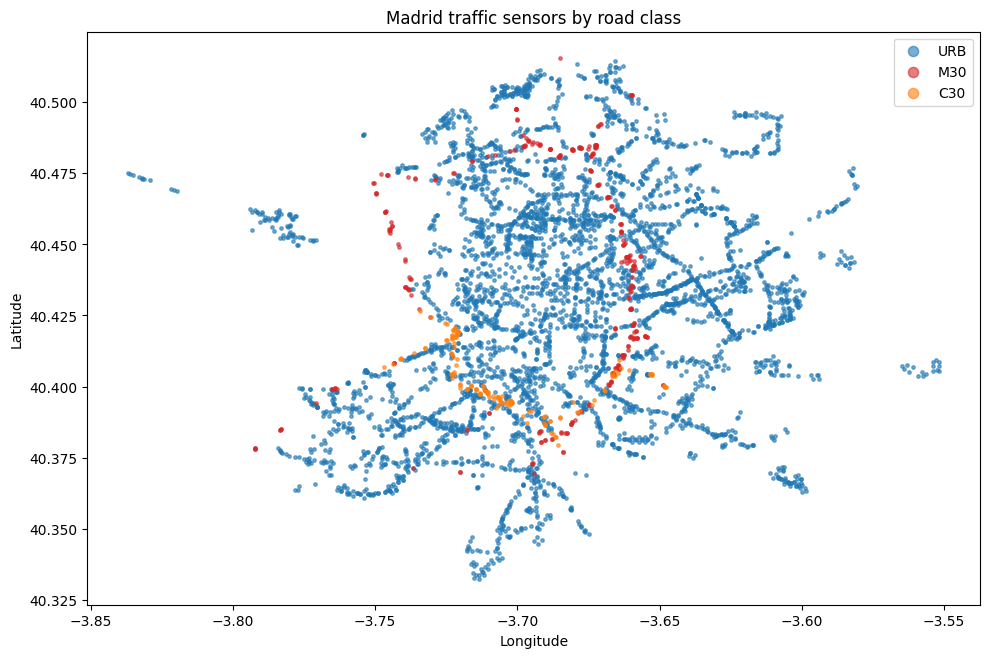

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

colors = {"URB": "tab:blue", "M30": "tab:red", "C30": "tab:orange"}

for elem_type, color in colors.items():
    subset = sensor_road_attrs[sensor_road_attrs["ELEMENT_TYPE"] == elem_type]
    ax.scatter(subset["LONGITUDE"], subset["LATITUDE"],
               s=6, alpha=0.6, label=elem_type, color=color)

ax.set_title("Madrid traffic sensors by road class")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(markerscale=3)
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/sensor_map_overview.png", dpi=200)
plt.show()

In [14]:
import folium

m = folium.Map(location=[40.4168, -3.7038], zoom_start=11, tiles="cartodbpositron")

colors = {"URB": "blue", "M30": "red", "C30": "orange"}

for _, row in sensor_road_attrs.iterrows():
    folium.CircleMarker(
        location=[row["LATITUDE"], row["LONGITUDE"]],
        radius=3,
        color=colors.get(row["ELEMENT_TYPE"], "gray"),
        fill=True,
        fill_opacity=0.7,
        popup=f"Sensor {row['SENSOR_ID']} | {row['ELEMENT_TYPE']} | "
              f"highway={row.get('highway')} | lanes={row.get('lanes')}"
    ).add_to(m)

m.save("/home/iai-labor/traffic_project/sensor_map_interactive.html")
m

In [15]:
weird_urb = sensor_road_attrs[
    (sensor_road_attrs["ELEMENT_TYPE"] == "URB") &
    (sensor_road_attrs["highway"].isin(["motorway", "trunk", "motorway_link", "trunk_link"]))
]
print(weird_urb.shape)
weird_urb[["SENSOR_ID", "LATITUDE", "LONGITUDE", "highway", "lanes"]]

(145, 18)


,SENSOR_ID,LATITUDE,LONGITUDE,highway,lanes
66,3414,40.438528,-3.659929,motorway_link,3
84,3434,40.438044,-3.683018,motorway_link,1
86,3436,40.390875,-3.677249,motorway_link,3
94,3445,40.364720,-3.713883,motorway_link,2
193,3562,40.432521,-3.688595,trunk,3
...,...,...,...,...,...
4494,11091,40.367978,-3.605805,motorway_link,3
4496,11093,40.365835,-3.606433,motorway_link,3
4724,11379,40.483912,-3.678159,motorway_link,1
4820,11508,40.502515,-3.696471,motorway_link,1


In [16]:
con.sql(f"""
    SELECT 
        CASE WHEN SENSOR_ID IN ({",".join(weird_urb["SENSOR_ID"].astype(str))})
             THEN 'URB_ramp' ELSE 'URB_normal' END AS sub_group,
        COUNT(*) AS n_rows,
        AVG(TRAFFIC_INTENSITY) AS avg_intensity,
        AVG(AVERAGE_SPEED) AS avg_speed,
        AVG(OCCUPANCY) AS avg_occupancy
    FROM read_parquet('{imputed_path}')
    WHERE ELEMENT_TYPE = 'URB'
    GROUP BY sub_group
""").show()

┌────────────┬───────────┬───────────────────┬───────────┬────────────────────┐
│ sub_group  │  n_rows   │   avg_intensity   │ avg_speed │   avg_occupancy    │
│  varchar   │   int64   │      double       │  double   │       double       │
├────────────┼───────────┼───────────────────┼───────────┼────────────────────┤
│ URB_ramp   │   4168479 │ 610.0667213767754 │       0.0 │ 7.6873399861057905 │
│ URB_normal │ 123496359 │ 256.8588533859203 │       0.0 │  5.198504086488191 │
└────────────┴───────────┴───────────────────┴───────────┴────────────────────┘



In [17]:
# Persist the sub-classification
weird_urb_ids = set(weird_urb["SENSOR_ID"])

con.sql(f"""
    COPY (
        SELECT *,
            CASE
                WHEN ELEMENT_TYPE = 'URB' AND SENSOR_ID IN ({",".join(map(str, weird_urb_ids))})
                    THEN 'URB_ramp'
                WHEN ELEMENT_TYPE = 'URB'
                    THEN 'URB_normal'
                ELSE ELEMENT_TYPE
            END AS ROAD_SUBCLASS
        FROM read_parquet('{imputed_path}')
    ) TO '/home/iai-labor/traffic_project/traffic_hourly_classified.parquet' (FORMAT PARQUET)
""")

In [18]:
con.sql(f"""
    SELECT ELEMENT_TYPE,
           AVG(TRAFFIC_INTENSITY) AS avg_intensity,
           AVG(OCCUPANCY) AS avg_occupancy,
           AVG(AVERAGE_SPEED) AS avg_speed
    FROM read_parquet('{imputed_path}')
    WHERE ELEMENT_TYPE IN ('M30', 'C30')
    GROUP BY ELEMENT_TYPE
""").show()

┌──────────────┬────────────────────┬───────────────────┬───────────────────┐
│ ELEMENT_TYPE │   avg_intensity    │   avg_occupancy   │     avg_speed     │
│   varchar    │       double       │      double       │      double       │
├──────────────┼────────────────────┼───────────────────┼───────────────────┤
│ C30          │   961.448928585692 │ 5.718261471271345 │ 48.32085811299627 │
│ M30          │ 1273.6564861169422 │ 5.611466767509308 │ 65.72494180251057 │
└──────────────┴────────────────────┴───────────────────┴───────────────────┘



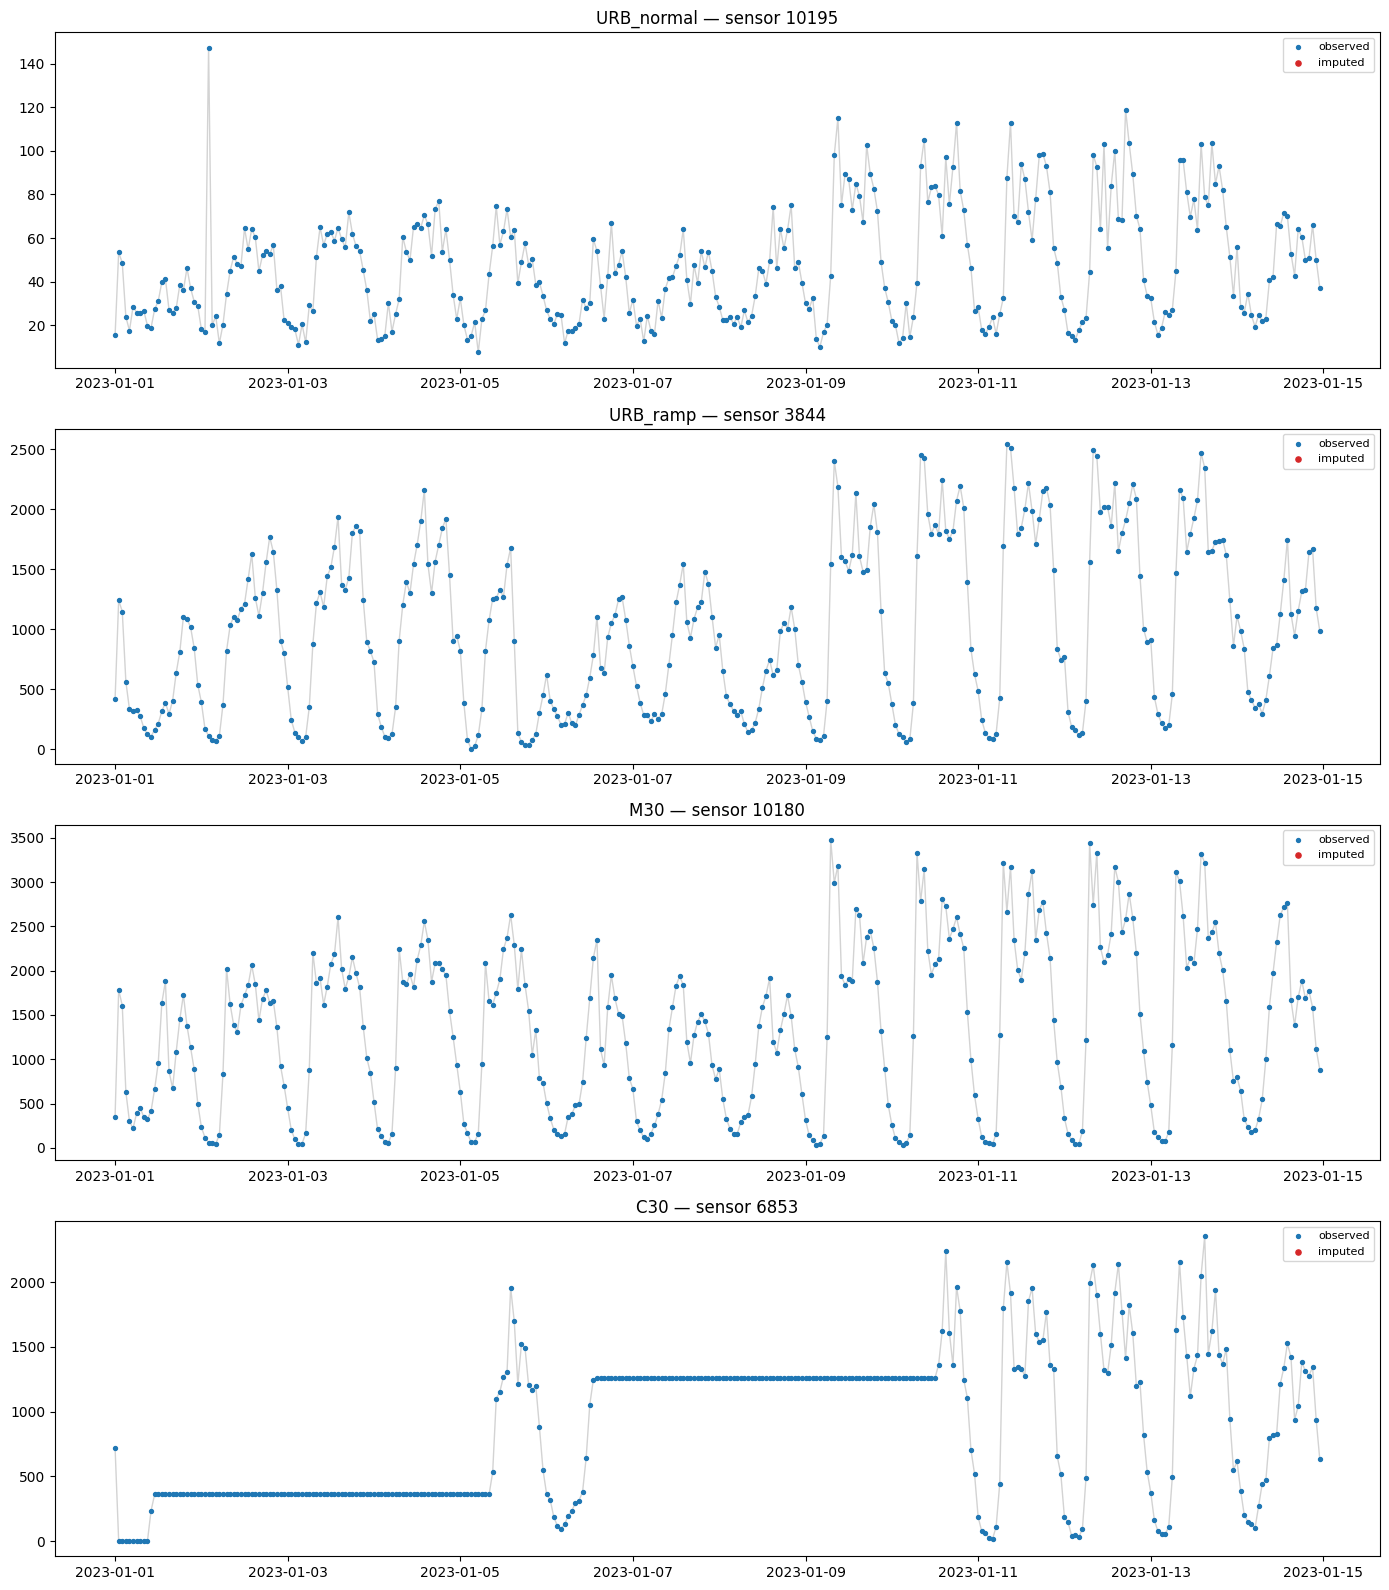

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

groups_query = {
    "URB_normal": f"ELEMENT_TYPE = 'URB' AND SENSOR_ID NOT IN ({','.join(map(str, weird_urb_ids))})",
    "URB_ramp":   f"ELEMENT_TYPE = 'URB' AND SENSOR_ID IN ({','.join(map(str, weird_urb_ids))})",
    "M30":        "ELEMENT_TYPE = 'M30'",
    "C30":        "ELEMENT_TYPE = 'C30'",
}

fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=False)

for ax, (label, cond) in zip(axes, groups_query.items()):
    # pick one representative sensor per group (the one with most rows = most complete history)
    rep_sensor = con.sql(f"""
        SELECT SENSOR_ID, COUNT(*) AS n
        FROM read_parquet('{imputed_path}')
        WHERE {cond}
        GROUP BY SENSOR_ID ORDER BY n DESC LIMIT 1
    """).df().iloc[0]["SENSOR_ID"]

    df = con.sql(f"""
        SELECT DATETIME, TRAFFIC_INTENSITY, IS_IMPUTED
        FROM read_parquet('{imputed_path}')
        WHERE SENSOR_ID = {rep_sensor}
        ORDER BY DATETIME
        LIMIT 336  -- 2 weeks of hourly data
    """).df()

    ax.plot(df["DATETIME"], df["TRAFFIC_INTENSITY"], color="lightgray", linewidth=1, zorder=1)
    observed = df[df["IS_IMPUTED"] == 0]
    imputed = df[df["IS_IMPUTED"] == 1]
    ax.scatter(observed["DATETIME"], observed["TRAFFIC_INTENSITY"], s=8, color="tab:blue", label="observed", zorder=2)
    ax.scatter(imputed["DATETIME"], imputed["TRAFFIC_INTENSITY"], s=14, color="tab:red", label="imputed", zorder=3)
    ax.set_title(f"{label} — sensor {rep_sensor}")
    ax.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/imputation_before_after_by_group.png", dpi=200)
plt.show()

In [20]:
# Flag sensors with long runs of identical consecutive values (stuck sensor detection)
con.sql(f"""
    WITH flagged AS (
        SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY,
               TRAFFIC_INTENSITY = LAG(TRAFFIC_INTENSITY) OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME) AS same_as_prev
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
    )
    SELECT SENSOR_ID, COUNT(*) AS n_repeated_steps
    FROM flagged
    WHERE same_as_prev = TRUE
    GROUP BY SENSOR_ID
    ORDER BY n_repeated_steps DESC
    LIMIT 20
""").show()

┌───────────┬──────────────────┐
│ SENSOR_ID │ n_repeated_steps │
│   int64   │      int64       │
├───────────┼──────────────────┤
│      6905 │            17231 │
│      6904 │            17211 │
│      6906 │            17198 │
│      6857 │            16627 │
│      1025 │            16227 │
│      6900 │            16017 │
│      1035 │            15892 │
│      1024 │            15833 │
│      6841 │            15754 │
│      6899 │            15742 │
│      7120 │            15689 │
│      6883 │            15686 │
│      1026 │            15668 │
│      1030 │            15632 │
│      6901 │            15629 │
│      6903 │            15562 │
│      1029 │            15539 │
│      1045 │            15467 │
│      1028 │            15456 │
│      6862 │            13676 │
└───────────┴──────────────────┘
  20 rows            2 columns



In [21]:
con.sql(f"""
    WITH flagged AS (
        SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY,
               TRAFFIC_INTENSITY = LAG(TRAFFIC_INTENSITY) OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME) AS same_as_prev
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
    )
    SELECT SENSOR_ID,
           COUNT(*) AS n_total,
           COUNT(*) FILTER (WHERE same_as_prev) AS n_repeated,
           ROUND(100.0 * COUNT(*) FILTER (WHERE same_as_prev) / COUNT(*), 1) AS pct_repeated
    FROM flagged
    GROUP BY SENSOR_ID
    ORDER BY pct_repeated DESC
    LIMIT 30
""").show()

# Class-level summary: is this a C30-specific problem or universal?
con.sql(f"""
    WITH flagged AS (
        SELECT ELEMENT_TYPE, SENSOR_ID, DATETIME, TRAFFIC_INTENSITY,
               TRAFFIC_INTENSITY = LAG(TRAFFIC_INTENSITY) OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME) AS same_as_prev
        FROM read_parquet('{imputed_path}')
    )
    SELECT ELEMENT_TYPE,
           ROUND(100.0 * COUNT(*) FILTER (WHERE same_as_prev) / COUNT(*), 2) AS pct_repeated_overall
    FROM flagged
    GROUP BY ELEMENT_TYPE
""").show()

┌───────────┬─────────┬────────────┬──────────────┐
│ SENSOR_ID │ n_total │ n_repeated │ pct_repeated │
│   int64   │  int64  │   int64    │    double    │
├───────────┼─────────┼────────────┼──────────────┤
│     11500 │     778 │        777 │         99.9 │
│     11486 │     778 │        777 │         99.9 │
│     11492 │     778 │        777 │         99.9 │
│     11501 │     778 │        777 │         99.9 │
│     11503 │     778 │        762 │         97.9 │
│     11502 │     778 │        753 │         96.8 │
│      6905 │   29928 │      17231 │         57.6 │
│      6904 │   29928 │      17211 │         57.5 │
│      6906 │   29928 │      17198 │         57.5 │
│      6857 │   29928 │      16627 │         55.6 │
│        ·  │     ·   │        ·   │           ·  │
│        ·  │     ·   │        ·   │           ·  │
│        ·  │     ·   │        ·   │           ·  │
│      6901 │   29928 │      15629 │         52.2 │
│      6903 │   29928 │      15562 │         52.0 │
│      1029 

In [22]:
con.sql(f"""
    WITH flagged AS (
        SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY,
               TRAFFIC_INTENSITY = LAG(TRAFFIC_INTENSITY) OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME) AS same_as_prev
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
    )
    SELECT SENSOR_ID,
           COUNT(*) FILTER (WHERE same_as_prev AND TRAFFIC_INTENSITY > 0) AS n_repeated_nonzero,
           COUNT(*) FILTER (WHERE same_as_prev AND TRAFFIC_INTENSITY = 0) AS n_repeated_zero
    FROM flagged
    GROUP BY SENSOR_ID
    ORDER BY n_repeated_nonzero DESC
    LIMIT 20
""").show()

┌───────────┬────────────────────┬─────────────────┐
│ SENSOR_ID │ n_repeated_nonzero │ n_repeated_zero │
│   int64   │       int64        │      int64      │
├───────────┼────────────────────┼─────────────────┤
│      6858 │               8835 │            2163 │
│      7122 │               6276 │            6918 │
│      6873 │               4632 │             715 │
│      6855 │               4571 │             700 │
│      1044 │               4403 │             247 │
│      6884 │               4287 │             799 │
│      6878 │               4272 │             263 │
│      6833 │               4237 │             707 │
│      6882 │               4234 │             272 │
│      1041 │               4208 │             199 │
│      1010 │               4199 │              33 │
│      6835 │               4183 │             724 │
│      6839 │               4182 │             230 │
│      1031 │               4156 │             175 │
│      6827 │               4137 │            

In [23]:
con.sql(f"""
    WITH runs AS (
        SELECT *,
            ROW_NUMBER() OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME)
            - ROW_NUMBER() OVER (PARTITION BY SENSOR_ID, TRAFFIC_INTENSITY ORDER BY DATETIME) AS grp
        FROM read_parquet('{imputed_path}')
    ),
    run_lengths AS (
        SELECT SENSOR_ID, ELEMENT_TYPE, TRAFFIC_INTENSITY, grp,
               COUNT(*) AS run_length,
               MIN(DATETIME) AS run_start, MAX(DATETIME) AS run_end
        FROM runs
        GROUP BY SENSOR_ID, ELEMENT_TYPE, TRAFFIC_INTENSITY, grp
    )
    SELECT ELEMENT_TYPE,
           COUNT(*) FILTER (WHERE run_length >= 3 AND TRAFFIC_INTENSITY > 0) AS n_stuck_runs,
           SUM(run_length) FILTER (WHERE run_length >= 3 AND TRAFFIC_INTENSITY > 0) AS n_stuck_hours
    FROM run_lengths
    GROUP BY ELEMENT_TYPE
""").show()

┌──────────────┬──────────────┬───────────────┐
│ ELEMENT_TYPE │ n_stuck_runs │ n_stuck_hours │
│   varchar    │    int64     │    int128     │
├──────────────┼──────────────┼───────────────┤
│ C30          │         6709 │        424989 │
│ M30          │          142 │           523 │
│ URB          │        57381 │        334313 │
└──────────────┴──────────────┴───────────────┘



In [24]:
con.sql(f"""
    WITH runs AS (
        SELECT *,
            ROW_NUMBER() OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME)
            - ROW_NUMBER() OVER (PARTITION BY SENSOR_ID, TRAFFIC_INTENSITY ORDER BY DATETIME) AS grp
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
    ),
    run_lengths AS (
        SELECT SENSOR_ID, TRAFFIC_INTENSITY, grp, COUNT(*) AS run_length
        FROM runs GROUP BY SENSOR_ID, TRAFFIC_INTENSITY, grp
    ),
    stuck_hours AS (
        SELECT SENSOR_ID, SUM(run_length) AS n_stuck
        FROM run_lengths
        WHERE run_length >= 3 AND TRAFFIC_INTENSITY > 0
        GROUP BY SENSOR_ID
    ),
    base AS (
        SELECT SENSOR_ID, COUNT(*) AS n_total,
               COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) AS n_missing
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
        GROUP BY SENSOR_ID
    )
    SELECT b.SENSOR_ID, b.n_total, b.n_missing,
           COALESCE(s.n_stuck, 0) AS n_stuck,
           ROUND(100.0 * (b.n_missing + COALESCE(s.n_stuck,0)) / b.n_total, 1) AS pct_unreliable
    FROM base b LEFT JOIN stuck_hours s USING (SENSOR_ID)
    ORDER BY pct_unreliable DESC
""").df()

,SENSOR_ID,n_total,n_missing,n_stuck,pct_unreliable
0,11501,778,0,778.0,100.0
1,11500,778,0,778.0,100.0
2,11502,778,0,758.0,97.4
3,11503,778,0,758.0,97.4
4,11489,3624,743,1262.0,55.3
...,...,...,...,...,...
142,6860,778,0,0.0,0.0
143,11493,636,0,0.0,0.0
144,11490,778,0,0.0,0.0
145,6861,778,0,0.0,0.0


In [25]:
df = con.sql(f"""
    WITH runs AS (
        SELECT *,
            ROW_NUMBER() OVER (PARTITION BY SENSOR_ID ORDER BY DATETIME)
            - ROW_NUMBER() OVER (PARTITION BY SENSOR_ID, TRAFFIC_INTENSITY ORDER BY DATETIME) AS grp
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
    ),
    run_lengths AS (
        SELECT SENSOR_ID, TRAFFIC_INTENSITY, grp, COUNT(*) AS run_length
        FROM runs GROUP BY SENSOR_ID, TRAFFIC_INTENSITY, grp
    ),
    stuck_hours AS (
        SELECT SENSOR_ID, SUM(run_length) AS n_stuck
        FROM run_lengths
        WHERE run_length >= 3 AND TRAFFIC_INTENSITY > 0
        GROUP BY SENSOR_ID
    ),
    base AS (
        SELECT SENSOR_ID, COUNT(*) AS n_total,
               COUNT(*) FILTER (WHERE TRAFFIC_INTENSITY IS NULL) AS n_missing
        FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = 'C30'
        GROUP BY SENSOR_ID
    )
    SELECT b.SENSOR_ID, b.n_total, b.n_missing,
           COALESCE(s.n_stuck, 0) AS n_stuck,
           ROUND(100.0 * (b.n_missing + COALESCE(s.n_stuck,0)) / b.n_total, 1) AS pct_unreliable
    FROM base b LEFT JOIN stuck_hours s USING (SENSOR_ID)
    ORDER BY pct_unreliable DESC
""").df()  # reuse from last query

import pandas as pd
bins = [0, 0.001, 5, 20, 50, 100.001]
labels = ["clean (0%)", "minor (0-5%)", "moderate (5-20%)", "major (20-50%)", "severe (50-100%)"]
df["tier"] = pd.cut(df["pct_unreliable"], bins=bins, labels=labels, right=False, include_lowest=True)

summary = df.groupby("tier", observed=True).agg(
    n_sensors=("SENSOR_ID", "count"),
    total_rows=("n_total", "sum")
)
print(summary)

                  n_sensors  total_rows
tier                                   
clean (0%)               12        9194
minor (0-5%)              1         778
moderate (5-20%)         93     2748215
major (20-50%)           35      883192
severe (50-100%)          6       36664


In [26]:
con.sql(f"""
    SELECT SENSOR_ID, MIN(DATETIME) AS first_seen, MAX(DATETIME) AS last_seen
    FROM read_parquet('{imputed_path}')
    WHERE SENSOR_ID IN (11501, 11500, 11503, 11502, 11489)
    GROUP BY SENSOR_ID
""").show()

┌───────────┬─────────────────────┬─────────────────────┐
│ SENSOR_ID │     first_seen      │      last_seen      │
│   int64   │      timestamp      │      timestamp      │
├───────────┼─────────────────────┼─────────────────────┤
│     11500 │ 2026-01-01 00:00:00 │ 2026-02-02 09:00:00 │
│     11501 │ 2026-01-01 00:00:00 │ 2026-02-02 09:00:00 │
│     11503 │ 2026-01-01 00:00:00 │ 2026-02-02 09:00:00 │
│     11489 │ 2026-01-01 00:00:00 │ 2026-05-31 23:00:00 │
│     11502 │ 2026-01-01 00:00:00 │ 2026-02-02 09:00:00 │
└───────────┴─────────────────────┴─────────────────────┘



In [27]:
import duckdb
import pandas as pd
import numpy as np

con = duckdb.connect()
imputed_path = "/home/iai-labor/traffic_project/traffic_hourly_imputed_parts/*.parquet"

# Per-class stuck-run thresholds, based on what we found:
# C30: even 3h+ nonzero repeats are real faults (avg stuck run was ~63h)
# URB: need a longer threshold to avoid flagging legitimate quiet-night flatlines
# M30: negligible issue, default to a conservative 6h anyway
STUCK_THRESHOLD_HOURS = {"C30": 3, "URB": 6, "M30": 6}

# Sensors to drop outright (severe tier, >=50% unreliable) — from your C30 analysis
SENSORS_TO_DROP = [11500, 11501, 11502, 11503]  # confirm/add the other 2 severe-tier IDs

In [28]:
def detect_stuck_runs(df, threshold_hours):
    """
    df must have columns: SENSOR_ID, DATETIME, TRAFFIC_INTENSITY (sorted by SENSOR_ID, DATETIME)
    Flags any run of >= threshold_hours consecutive identical NONZERO values as stuck.
    Returns df with new column IS_STUCK (bool).
    """
    df = df.sort_values(["SENSOR_ID", "DATETIME"]).reset_index(drop=True)

    # run-length-encode consecutive identical values per sensor
    same_as_prev = (
        (df["TRAFFIC_INTENSITY"] == df.groupby("SENSOR_ID")["TRAFFIC_INTENSITY"].shift(1))
    ).fillna(False)

    # new run starts wherever value changes (or sensor changes)
    new_run = (~same_as_prev) | (df["SENSOR_ID"] != df["SENSOR_ID"].shift(1))
    run_id = new_run.cumsum()

    run_lengths = df.groupby(run_id)["TRAFFIC_INTENSITY"].transform("size")
    run_value_nonzero = df["TRAFFIC_INTENSITY"] > 0

    df["IS_STUCK"] = (run_lengths >= threshold_hours) & run_value_nonzero
    return df

In [29]:
def reimpute_with_stuck_handling(df, threshold_hours, max_gap_hours=24):
    """
    df: single ELEMENT_TYPE's data, columns SENSOR_ID, DATETIME, TRAFFIC_INTENSITY (+ existing flags ok to drop/recompute)
    1. Detects stuck runs and treats them as missing
    2. Combines with existing missingness
    3. Recomputes gap lengths on the combined missing set
    4. Linearly interpolates gaps <= max_gap_hours per sensor
    5. Leaves longer gaps as NaN (untouched, to be handled by exclusion/other strategy later)
    """
    df = detect_stuck_runs(df, threshold_hours)

    df["TRAFFIC_INTENSITY_RAW"] = df["TRAFFIC_INTENSITY"]  # keep original for audit
    df.loc[df["IS_STUCK"], "TRAFFIC_INTENSITY"] = np.nan

    out_frames = []
    for sensor_id, g in df.groupby("SENSOR_ID"):
        g = g.sort_values("DATETIME").reset_index(drop=True)

        is_na = g["TRAFFIC_INTENSITY"].isna()
        # run-length-encode NaN gaps
        gap_group = (is_na != is_na.shift(1)).cumsum()
        gap_len = g.groupby(gap_group)["TRAFFIC_INTENSITY"].transform("size")
        g["GAP_LENGTH_HOURS_V2"] = np.where(is_na, gap_len, 0)

        # interpolate only gaps <= max_gap_hours
        fillable = is_na & (gap_len <= max_gap_hours)
        g["TRAFFIC_INTENSITY_INTERP"] = g["TRAFFIC_INTENSITY"].interpolate(
            method="linear", limit_area="inside"
        )
        g["TRAFFIC_INTENSITY_FINAL"] = np.where(
            fillable, g["TRAFFIC_INTENSITY_INTERP"], g["TRAFFIC_INTENSITY"]
        )
        g["IS_IMPUTED_V2"] = fillable & g["TRAFFIC_INTENSITY_FINAL"].notna()

        out_frames.append(g)

    return pd.concat(out_frames, ignore_index=True)

In [30]:
# Run it for C30 first (manageable size — ~3.68M rows fits comfortably in pandas)
c30_raw = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY
    FROM read_parquet('{imputed_path}')
    WHERE ELEMENT_TYPE = 'C30'
      AND SENSOR_ID NOT IN ({",".join(map(str, SENSORS_TO_DROP))})
    ORDER BY SENSOR_ID, DATETIME
""").df()

c30_fixed = reimpute_with_stuck_handling(
    c30_raw, threshold_hours=STUCK_THRESHOLD_HOURS["C30"], max_gap_hours=24
)

print(c30_fixed.shape)
print("Stuck rows flagged:", c30_fixed["IS_STUCK"].sum())
print("Newly imputed rows:", c30_fixed["IS_IMPUTED_V2"].sum())
print("Still missing after fix:", c30_fixed["TRAFFIC_INTENSITY_FINAL"].isna().sum())

(3674931, 9)
Stuck rows flagged: 421917
Newly imputed rows: 33059
Still missing after fix: 711663


In [31]:
# How is the remaining 711,663 distributed — concentrated in a few sensors, or spread out?
remaining = c30_fixed[c30_fixed["TRAFFIC_INTENSITY_FINAL"].isna()]

per_sensor_remaining = (
    remaining.groupby("SENSOR_ID").size()
    .div(c30_fixed.groupby("SENSOR_ID").size())
    .mul(100)
    .sort_values(ascending=False)
)
print(per_sensor_remaining.head(20))
print("\nSensors still >50% missing after fix:", (per_sensor_remaining > 50).sum())
print("Sensors now <5% missing after fix:", (per_sensor_remaining < 5).sum())

SENSOR_ID
11489    55.325607
1001     52.345630
6836     47.590885
1003     46.558407
1002     42.027533
7117     40.482184
1014     40.258819
1018     39.113873
1016     37.172547
1013     37.028869
1012     36.496501
7145     36.113339
6858     35.257952
6873     35.237904
1021     32.823135
1015     31.746191
1010     27.947073
3545     27.402433
6886     27.161855
3546     25.568030
dtype: float64

Sensors still >50% missing after fix: 2
Sensors now <5% missing after fix: 0


In [32]:
print(per_sensor_remaining.describe())
print()
print("Distribution buckets after fix:")
bins = [0, 5, 10, 20, 50, 100.001]
labels = ["<5%", "5-10%", "10-20%", "20-50%", "50%+"]
tier = pd.cut(per_sensor_remaining, bins=bins, labels=labels, right=False)
print(tier.value_counts().sort_index())

count    130.000000
mean      19.745035
std        8.706787
min       10.986367
25%       15.274158
50%       15.761160
75%       20.666592
max       55.325607
dtype: float64

Distribution buckets after fix:
<5%        0
5-10%      0
10-20%    93
20-50%    35
50%+       2
Name: count, dtype: int64


In [33]:
c30_fixed.groupby("SENSOR_ID").size().loc[per_sensor_remaining.head(20).index]

SENSOR_ID
11489     3624
1001     29928
6836     29928
1003     29928
1002     29928
7117     28205
1014     28205
1018     29928
1016     29928
1013     29928
1012     29148
7145     29928
6858     29928
6873     29928
1021     29531
1015     29928
1010     29928
3545     29928
6886     29928
3546     29928
dtype: int64

In [34]:
def seasonal_fill(df):
    """
    Fills remaining NaNs in TRAFFIC_INTENSITY_FINAL using each sensor's own
    historical median for the same (day_of_week, hour) combination.
    Only fills if the sensor has at least some historical data for that slot.
    """
    df = df.copy()
    df["DATETIME"] = pd.to_datetime(df["DATETIME"])
    df["hour"] = df["DATETIME"].dt.hour
    df["dow"] = df["DATETIME"].dt.dayofweek

    # per-sensor, per (dow, hour) median from OBSERVED (non-imputed, non-stuck) values only
    seasonal_lookup = (
        df[~df["IS_STUCK"] & df["TRAFFIC_INTENSITY_RAW"].notna()]
        .groupby(["SENSOR_ID", "dow", "hour"])["TRAFFIC_INTENSITY_RAW"]
        .median()
        .rename("SEASONAL_FILL_VALUE")
        .reset_index()
    )

    df = df.merge(seasonal_lookup, on=["SENSOR_ID", "dow", "hour"], how="left")

    still_missing = df["TRAFFIC_INTENSITY_FINAL"].isna()
    df["IS_SEASONAL_FILLED"] = still_missing & df["SEASONAL_FILL_VALUE"].notna()
    df["TRAFFIC_INTENSITY_FINAL"] = np.where(
        df["IS_SEASONAL_FILLED"], df["SEASONAL_FILL_VALUE"], df["TRAFFIC_INTENSITY_FINAL"]
    )
    return df.drop(columns=["hour", "dow"])

In [35]:
c30_final = seasonal_fill(c30_fixed)

print("Still missing after seasonal fill:", c30_final["TRAFFIC_INTENSITY_FINAL"].isna().sum())
print("Seasonally filled rows:", c30_final["IS_SEASONAL_FILLED"].sum())
print("Total fill breakdown:")
print(pd.Series({
    "original_observed": (~c30_final["IS_STUCK"] & c30_final["TRAFFIC_INTENSITY_RAW"].notna()).sum(),
    "linear_interpolated": c30_final["IS_IMPUTED_V2"].sum(),
    "seasonal_filled": c30_final["IS_SEASONAL_FILLED"].sum(),
    "still_missing": c30_final["TRAFFIC_INTENSITY_FINAL"].isna().sum(),
}))

Still missing after seasonal fill: 0
Seasonally filled rows: 711663
Total fill breakdown:
original_observed      2930209
linear_interpolated      33059
seasonal_filled         711663
still_missing                0
dtype: int64


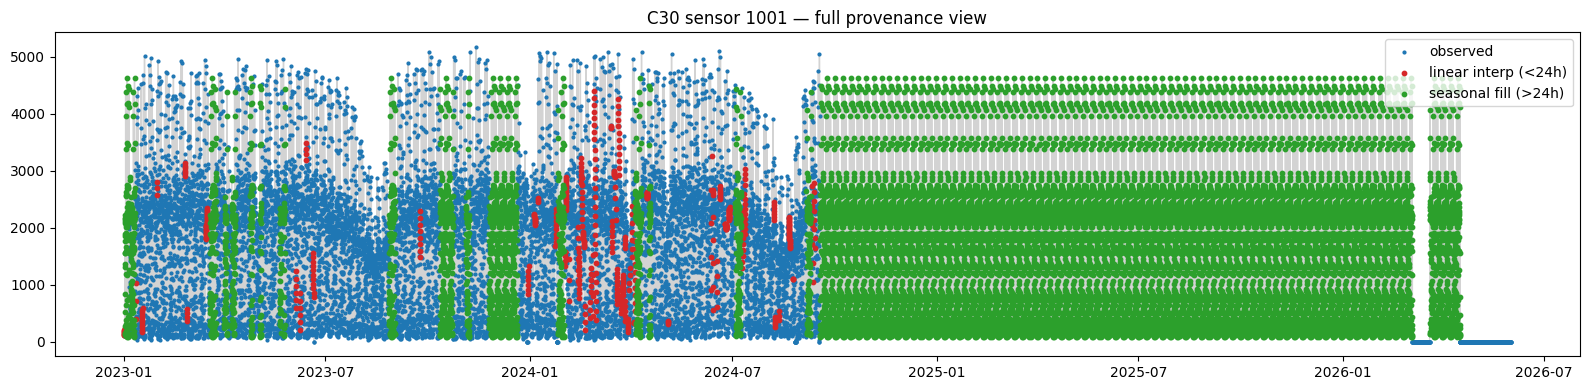

In [36]:
import matplotlib.pyplot as plt

# Pick a sensor known to have a long gap, e.g. one of the high-missing ones from earlier
check_sensor = 1001
g = c30_final[c30_final["SENSOR_ID"] == check_sensor].sort_values("DATETIME")

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(g["DATETIME"], g["TRAFFIC_INTENSITY_FINAL"], color="lightgray", linewidth=1, zorder=1)

obs = g[(~g["IS_STUCK"]) & g["TRAFFIC_INTENSITY_RAW"].notna()]
interp = g[g["IS_IMPUTED_V2"]]
seas = g[g["IS_SEASONAL_FILLED"]]

ax.scatter(obs["DATETIME"], obs["TRAFFIC_INTENSITY_FINAL"], s=4, color="tab:blue", label="observed")
ax.scatter(interp["DATETIME"], interp["TRAFFIC_INTENSITY_FINAL"], s=10, color="tab:red", label="linear interp (<24h)")
ax.scatter(seas["DATETIME"], seas["TRAFFIC_INTENSITY_FINAL"], s=10, color="tab:green", label="seasonal fill (>24h)")
ax.set_title(f"C30 sensor {check_sensor} — full provenance view")
ax.legend()
plt.tight_layout()
plt.show()

In [37]:
m30_raw = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY
    FROM read_parquet('{imputed_path}') WHERE ELEMENT_TYPE = 'M30'
    ORDER BY SENSOR_ID, DATETIME
""").df()
m30_fixed = reimpute_with_stuck_handling(m30_raw, threshold_hours=STUCK_THRESHOLD_HOURS["M30"])
m30_final = seasonal_fill(m30_fixed)

urb_raw = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY
    FROM read_parquet('{imputed_path}') WHERE ELEMENT_TYPE = 'URB'
    ORDER BY SENSOR_ID, DATETIME
""").df()
urb_fixed = reimpute_with_stuck_handling(urb_raw, threshold_hours=STUCK_THRESHOLD_HOURS["URB"])
urb_final = seasonal_fill(urb_fixed)

In [38]:
def seasonal_fill_with_cap(df, max_seasonal_fraction=0.3):
    """
    Same as seasonal_fill, but if a sensor's total seasonal-fill share would exceed
    max_seasonal_fraction, that sensor is flagged as unreliable instead of filled.
    """
    df = seasonal_fill(df)  # reuse logic from before

    sensor_fill_rate = df.groupby("SENSOR_ID")["IS_SEASONAL_FILLED"].mean()
    bad_sensors = sensor_fill_rate[sensor_fill_rate > max_seasonal_fraction].index

    df["SENSOR_EXCLUDED_TOO_MUCH_FILL"] = df["SENSOR_ID"].isin(bad_sensors)
    # undo the fill for excluded sensors — leave them genuinely NaN, to be dropped/handled separately
    mask = df["SENSOR_ID"].isin(bad_sensors) & df["IS_SEASONAL_FILLED"]
    df.loc[mask, "TRAFFIC_INTENSITY_FINAL"] = np.nan
    df.loc[mask, "IS_SEASONAL_FILLED"] = False

    return df, bad_sensors

In [39]:
c30_final, c30_bad_sensors = seasonal_fill_with_cap(c30_fixed, max_seasonal_fraction=0.3)
print(f"Sensors excluded (too much fill needed): {len(c30_bad_sensors)}")
print(c30_bad_sensors.tolist())
print("\nRevised breakdown:")
print(pd.Series({
    "original_observed": (~c30_final["IS_STUCK"] & c30_final["TRAFFIC_INTENSITY_RAW"].notna()).sum(),
    "linear_interpolated": c30_final["IS_IMPUTED_V2"].sum(),
    "seasonal_filled": c30_final["IS_SEASONAL_FILLED"].sum(),
    "still_missing": c30_final["TRAFFIC_INTENSITY_FINAL"].isna().sum(),
}))

Sensors excluded (too much fill needed): 16
[1001, 1002, 1003, 1012, 1013, 1014, 1015, 1016, 1018, 1021, 6836, 6858, 6873, 7117, 7145, 11489]

Revised breakdown:
original_observed      2930209
linear_interpolated      33059
seasonal_filled         534813
still_missing           176850
dtype: int64


In [40]:
# Is the remaining missingness now spread thinly across many sensors (fine, leave as NaN),
# or still concentrated in a few sensors that should also be excluded?
still_missing_df = c30_final[c30_final["TRAFFIC_INTENSITY_FINAL"].isna()]
per_sensor_still = (
    still_missing_df.groupby("SENSOR_ID").size()
    .div(c30_final.groupby("SENSOR_ID").size())
    .mul(100)
    .sort_values(ascending=False)
)
print(per_sensor_still.head(15))
print("\nMax remaining missing %:", per_sensor_still.max())

SENSOR_ID
11489    55.325607
1001     52.345630
6836     47.590885
1003     46.558407
1002     42.027533
7117     40.482184
1014     40.258819
1018     39.113873
1016     37.172547
1013     37.028869
1012     36.496501
7145     36.113339
6858     35.257952
6873     35.237904
1021     32.823135
dtype: float64

Max remaining missing %: 55.32560706401766


In [41]:
con.sql(f"""
    SELECT SENSOR_ID, MIN(DATETIME) FILTER (WHERE TRAFFIC_INTENSITY IS NOT NULL) AS last_meaningful_data
    FROM (
        SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY
        FROM read_parquet('{imputed_path}')
        WHERE SENSOR_ID IN (1001,1002,1003,1012,1013,1014,1015,1016,1018,1021,6836,6858,6873,7117,7145,11489)
    )
    GROUP BY SENSOR_ID
""").show()

┌───────────┬──────────────────────┐
│ SENSOR_ID │ last_meaningful_data │
│   int64   │      timestamp       │
├───────────┼──────────────────────┤
│      1013 │ 2023-01-01 00:00:00  │
│      1021 │ 2023-01-17 13:00:00  │
│      6873 │ 2023-01-01 00:00:00  │
│      1018 │ 2023-01-01 00:00:00  │
│      1016 │ 2023-01-01 00:00:00  │
│     11489 │ 2026-01-01 00:00:00  │
│      6858 │ 2023-01-01 00:00:00  │
│      1002 │ 2023-01-01 00:00:00  │
│      1015 │ 2023-01-01 00:00:00  │
│      1003 │ 2023-01-01 00:00:00  │
│      6836 │ 2023-01-01 00:00:00  │
│      7117 │ 2023-01-01 00:00:00  │
│      1001 │ 2023-01-01 00:00:00  │
│      1012 │ 2023-01-01 00:00:00  │
│      7145 │ 2023-01-01 00:00:00  │
│      1014 │ 2023-01-01 00:00:00  │
└───────────┴──────────────────────┘
  16 rows                2 columns



In [42]:
con.sql(f"""
    SELECT SENSOR_ID, MAX(DATETIME) AS last_real_reading
    FROM read_parquet('{imputed_path}')
    WHERE SENSOR_ID IN (1001,1002,1003,1012,1013,1014,1015,1016,1018,1021,6836,6858,6873,7117,7145,11489)
      AND TRAFFIC_INTENSITY IS NOT NULL
    GROUP BY SENSOR_ID
    ORDER BY last_real_reading
""").show()

┌───────────┬─────────────────────┐
│ SENSOR_ID │  last_real_reading  │
│   int64   │      timestamp      │
├───────────┼─────────────────────┤
│      1014 │ 2026-03-21 04:00:00 │
│      7117 │ 2026-03-21 04:00:00 │
│      1012 │ 2026-04-29 11:00:00 │
│      6873 │ 2026-05-31 23:00:00 │
│      1013 │ 2026-05-31 23:00:00 │
│      1021 │ 2026-05-31 23:00:00 │
│     11489 │ 2026-05-31 23:00:00 │
│      1016 │ 2026-05-31 23:00:00 │
│      1018 │ 2026-05-31 23:00:00 │
│      6858 │ 2026-05-31 23:00:00 │
│      7145 │ 2026-05-31 23:00:00 │
│      1002 │ 2026-05-31 23:00:00 │
│      1003 │ 2026-05-31 23:00:00 │
│      1015 │ 2026-05-31 23:00:00 │
│      6836 │ 2026-05-31 23:00:00 │
│      1001 │ 2026-05-31 23:00:00 │
└───────────┴─────────────────────┘
  16 rows               2 columns



In [43]:
con.sql(f"""
    SELECT SENSOR_ID, LATITUDE, LONGITUDE
    FROM read_parquet('{imputed_path}')
    WHERE SENSOR_ID IN (1001,1002,1003,1012,1013,1014,1015,1016,1018,1021,6836,6858,6873,7117,7145,11489)
    GROUP BY SENSOR_ID, LATITUDE, LONGITUDE
""").df()

,SENSOR_ID,LATITUDE,LONGITUDE
0,1013,40.419971,-3.722532
1,1002,40.408030,-3.743760
2,6873,40.391412,-3.695889
3,6858,40.397749,-3.710660
4,1014,40.419889,-3.722677
5,1003,40.406824,-3.746834
6,1021,40.393484,-3.702727
7,6836,40.418064,-3.721338
8,7145,40.397339,-3.710482
9,1015,40.420488,-3.721843


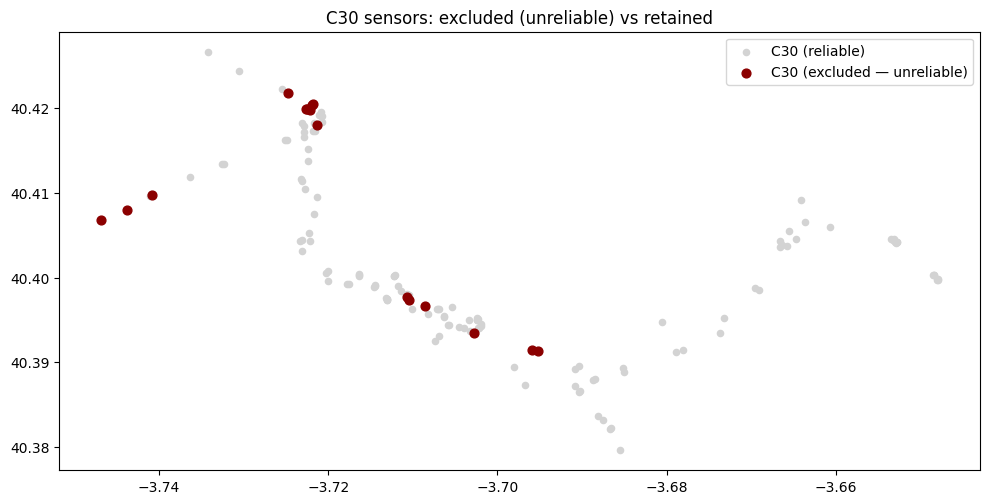

In [44]:
fig, ax = plt.subplots(figsize=(10, 10))

c30_all = sensor_road_attrs[sensor_road_attrs["ELEMENT_TYPE"] == "C30"]
bad_ids = [1001,1002,1003,1012,1013,1014,1015,1016,1018,1021,6836,6858,6873,7117,7145,11489]

ax.scatter(c30_all["LONGITUDE"], c30_all["LATITUDE"], s=20, color="lightgray", label="C30 (reliable)")
bad = c30_all[c30_all["SENSOR_ID"].isin(bad_ids)]
ax.scatter(bad["LONGITUDE"], bad["LATITUDE"], s=40, color="darkred", label="C30 (excluded — unreliable)")

ax.set_title("C30 sensors: excluded (unreliable) vs retained")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("/home/iai-labor/traffic_project/c30_excluded_sensors_map.png", dpi=200)
plt.show()

In [45]:
m30_raw = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY
    FROM read_parquet('{imputed_path}')
    WHERE ELEMENT_TYPE = 'M30'
    ORDER BY SENSOR_ID, DATETIME
""").df()

m30_fixed = reimpute_with_stuck_handling(m30_raw, threshold_hours=STUCK_THRESHOLD_HOURS["M30"])
m30_final, m30_bad_sensors = seasonal_fill_with_cap(m30_fixed, max_seasonal_fraction=0.3)

print(f"M30 sensors excluded: {len(m30_bad_sensors)} of {m30_raw['SENSOR_ID'].nunique()}")
print(m30_bad_sensors.tolist())
print("\nBreakdown:")
print(pd.Series({
    "original_observed": (~m30_final["IS_STUCK"] & m30_final["TRAFFIC_INTENSITY_RAW"].notna()).sum(),
    "linear_interpolated": m30_final["IS_IMPUTED_V2"].sum(),
    "seasonal_filled": m30_final["IS_SEASONAL_FILLED"].sum(),
    "still_missing": m30_final["TRAFFIC_INTENSITY_FINAL"].isna().sum(),
}))

M30 sensors excluded: 4 of 304
[6703, 6704, 6756, 10173]

Breakdown:
original_observed      8492986
linear_interpolated        113
seasonal_filled          99948
still_missing            41365
dtype: int64


In [46]:
# Confirm still_missing rows belong only to the excluded sensors
still_missing_m30 = m30_final[m30_final["TRAFFIC_INTENSITY_FINAL"].isna()]
print(still_missing_m30["SENSOR_ID"].unique())
print(len(still_missing_m30), "rows, expected to match the 4 excluded sensors only")

[ 6703  6704  6756 10173]
41365 rows, expected to match the 4 excluded sensors only


In [47]:
import time

urb_raw = con.sql(f"""
    SELECT SENSOR_ID, DATETIME, TRAFFIC_INTENSITY
    FROM read_parquet('{imputed_path}')
    WHERE ELEMENT_TYPE = 'URB'
    ORDER BY SENSOR_ID, DATETIME
""").df()

print(urb_raw.shape)
print(urb_raw.memory_usage(deep=True).sum() / 1e9, "GB in memory")

(127664838, 3)
3.063956244 GB in memory


In [48]:
def reimpute_with_stuck_handling_fast(df, threshold_hours, max_gap_hours=24):
    df = df.sort_values(["SENSOR_ID", "DATETIME"]).reset_index(drop=True)

    # --- stuck-run detection (vectorized, no loop) ---
    same_as_prev = (
        (df["TRAFFIC_INTENSITY"] == df.groupby("SENSOR_ID")["TRAFFIC_INTENSITY"].shift(1))
    ).fillna(False)
    new_run = (~same_as_prev) | (df["SENSOR_ID"] != df["SENSOR_ID"].shift(1))
    run_id = new_run.cumsum()
    run_lengths = df.groupby(run_id)["TRAFFIC_INTENSITY"].transform("size")
    df["IS_STUCK"] = (run_lengths >= threshold_hours) & (df["TRAFFIC_INTENSITY"] > 0)

    df["TRAFFIC_INTENSITY_RAW"] = df["TRAFFIC_INTENSITY"]
    df.loc[df["IS_STUCK"], "TRAFFIC_INTENSITY"] = np.nan

    # --- gap-length on combined missing set (vectorized) ---
    is_na = df["TRAFFIC_INTENSITY"].isna()
    new_gap = (is_na != is_na.shift(1)) | (df["SENSOR_ID"] != df["SENSOR_ID"].shift(1))
    gap_id = new_gap.cumsum()
    gap_len = df.groupby(gap_id)["TRAFFIC_INTENSITY"].transform("size")
    df["GAP_LENGTH_HOURS_V2"] = np.where(is_na, gap_len, 0)

    fillable = is_na & (gap_len <= max_gap_hours)

    # --- linear interpolation per sensor (still needs groupby, but only .interpolate, which is fast/vectorized internally) ---
    df["TRAFFIC_INTENSITY_INTERP"] = (
        df.groupby("SENSOR_ID")["TRAFFIC_INTENSITY"]
        .transform(lambda s: s.interpolate(method="linear", limit_area="inside"))
    )
    df["TRAFFIC_INTENSITY_FINAL"] = np.where(fillable, df["TRAFFIC_INTENSITY_INTERP"], df["TRAFFIC_INTENSITY"])
    df["IS_IMPUTED_V2"] = fillable & df["TRAFFIC_INTENSITY_FINAL"].notna()

    return df.drop(columns=["TRAFFIC_INTENSITY_INTERP"])

In [49]:
import time
t0 = time.time()
urb_fixed = reimpute_with_stuck_handling_fast(urb_raw, threshold_hours=STUCK_THRESHOLD_HOURS["URB"])
print("stuck+interp step:", time.time() - t0, "seconds")

t0 = time.time()
urb_final, urb_bad_sensors = seasonal_fill_with_cap(urb_fixed, max_seasonal_fraction=0.3)
print("seasonal fill step:", time.time() - t0, "seconds")

print(f"URB sensors excluded: {len(urb_bad_sensors)} of {urb_raw['SENSOR_ID'].nunique()}")
print("\nBreakdown:")
print(pd.Series({
    "original_observed": (~urb_final["IS_STUCK"] & urb_final["TRAFFIC_INTENSITY_RAW"].notna()).sum(),
    "linear_interpolated": urb_final["IS_IMPUTED_V2"].sum(),
    "seasonal_filled": urb_final["IS_SEASONAL_FILLED"].sum(),
    "still_missing": urb_final["TRAFFIC_INTENSITY_FINAL"].isna().sum(),
}))

stuck+interp step: 28.04955267906189 seconds
seasonal fill step: 25.831840753555298 seconds
URB sensors excluded: 41 of 4440

Breakdown:
original_observed      124215651
linear_interpolated       108979
seasonal_filled          2891600
still_missing             448608
dtype: int64


In [50]:
def make_breakdown(df, label):
    return pd.Series({
        "class": label,
        "n_sensors_total": df["SENSOR_ID"].nunique(),
        "observed": (~df["IS_STUCK"] & df["TRAFFIC_INTENSITY_RAW"].notna()).sum(),
        "linear_interp": df["IS_IMPUTED_V2"].sum(),
        "seasonal_fill": df["IS_SEASONAL_FILLED"].sum(),
        "still_missing": df["TRAFFIC_INTENSITY_FINAL"].isna().sum(),
        "total_rows": len(df),
    })

summary = pd.DataFrame([
    make_breakdown(urb_final, "URB"),
    make_breakdown(m30_final, "M30"),
    make_breakdown(c30_final, "C30"),
]).set_index("class")

for col in ["observed", "linear_interp", "seasonal_fill", "still_missing"]:
    summary[f"{col}_pct"] = (summary[col] / summary["total_rows"] * 100).round(2)

summary

,n_sensors_total,observed,linear_interp,seasonal_fill,still_missing,total_rows,observed_pct,linear_interp_pct,seasonal_fill_pct,still_missing_pct
class,,,,,,,,,,
URB,4440,124215651,108979,2891600,448608,127664838,97.30,0.09,2.26,0.35
M30,304,8492986,113,99948,41365,8634412,98.36,0.00,1.16,0.48
C30,143,2930209,33059,534813,176850,3674931,79.74,0.90,14.55,4.81


In [51]:
print(c30_final["SENSOR_ID"].nunique())
print(sorted(c30_final["SENSOR_ID"].unique())[:10])
# check whether the originally-dropped dead sensors crept back in
print(set([11500, 11501, 11502, 11503]) & set(c30_final["SENSOR_ID"].unique()))

143
[np.int64(1001), np.int64(1002), np.int64(1003), np.int64(1006), np.int64(1009), np.int64(1010), np.int64(1011), np.int64(1012), np.int64(1013), np.int64(1014)]
set()


In [52]:
import gc, os

def process_and_save_class(element_type, threshold_hours, max_seasonal_fraction=0.3):
    context_cols = """
        SENSOR_ID, DATETIME, TRAFFIC_INTENSITY, ELEMENT_TYPE, OCCUPANCY, LOAD, AVERAGE_SPEED,
        ERROR_FLAG, LONGITUDE, LATITUDE, NEAREST_WEATHER_STATION_CODE,
        BAROMETRIC_PRESSURE, PRECIPITATION, RELATIVE_HUMIDITY,
        SOLAR_RADIATION, TEMPERATURE, WIND_DIRECTION, WIND_SPEED
    """
    raw = con.sql(f"""
        SELECT {context_cols} FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = '{element_type}' ORDER BY SENSOR_ID, DATETIME
    """).df()

    fixed = reimpute_with_stuck_handling_fast(raw, threshold_hours=threshold_hours)
    del raw; gc.collect()

    final, bad_sensors = seasonal_fill_with_cap(fixed, max_seasonal_fraction=max_seasonal_fraction)
    del fixed; gc.collect()

    final["ROAD_CLASS"] = element_type
    out_path = f"/home/iai-labor/traffic_project/traffic_hourly_clean_{element_type}.parquet"
    final.to_parquet(out_path, index=False, compression="snappy")  # snappy keeps write fast + reasonably small

    print(f"{element_type}: saved {len(final):,} rows to {out_path}")
    print(f"File size: {os.path.getsize(out_path) / 1e9:.2f} GB")

    del final; gc.collect()
    return out_path, bad_sensors

In [58]:
import duckdb, gc, os
import pandas as pd
import numpy as np

con = duckdb.connect()
imputed_path = "/home/iai-labor/traffic_project/traffic_hourly_imputed_parts/*.parquet"

def process_class_chunked(element_type, threshold_hours, max_seasonal_fraction=0.3, 
                           batch_size=300, exclude_sensor_ids=None):
    context_cols = """
        SENSOR_ID, DATETIME, TRAFFIC_INTENSITY, ELEMENT_TYPE, OCCUPANCY, LOAD, AVERAGE_SPEED,
        ERROR_FLAG, LONGITUDE, LATITUDE, NEAREST_WEATHER_STATION_CODE,
        BAROMETRIC_PRESSURE, PRECIPITATION, RELATIVE_HUMIDITY,
        SOLAR_RADIATION, TEMPERATURE, WIND_DIRECTION, WIND_SPEED
    """
    exclude_clause = ""
    if exclude_sensor_ids:
        exclude_clause = f"AND SENSOR_ID NOT IN ({','.join(map(str, exclude_sensor_ids))})"

    sensor_ids = con.sql(f"""
        SELECT DISTINCT SENSOR_ID FROM read_parquet('{imputed_path}')
        WHERE ELEMENT_TYPE = '{element_type}' {exclude_clause}
        ORDER BY SENSOR_ID
    """).df()["SENSOR_ID"].tolist()

    print(f"{element_type}: {len(sensor_ids)} sensors, processing in batches of {batch_size}")

    out_dir = f"/home/iai-labor/traffic_project/chunks_{element_type}"
    os.makedirs(out_dir, exist_ok=True)
    all_bad_sensors = []

    for i in range(0, len(sensor_ids), batch_size):
        batch_ids = sensor_ids[i:i+batch_size]
        id_list = ",".join(map(str, batch_ids))

        raw = con.sql(f"""
            SELECT {context_cols} FROM read_parquet('{imputed_path}')
            WHERE SENSOR_ID IN ({id_list}) ORDER BY SENSOR_ID, DATETIME
        """).df()

        fixed = reimpute_with_stuck_handling_fast(raw, threshold_hours=threshold_hours)
        del raw; gc.collect()

        final, bad = seasonal_fill_with_cap(fixed, max_seasonal_fraction=max_seasonal_fraction)
        del fixed; gc.collect()

        final["ROAD_CLASS"] = element_type
        batch_path = f"{out_dir}/batch_{i:05d}.parquet"
        final.to_parquet(batch_path, index=False, compression="snappy")

        all_bad_sensors.extend(bad.tolist() if hasattr(bad, "tolist") else list(bad))
        n_done = i + len(batch_ids)
        print(f"  batch {i//batch_size + 1}: sensors {n_done}/{len(sensor_ids)} done, "
              f"{len(final):,} rows saved to {batch_path}")

        del final; gc.collect()

    # combine all batches into one file via DuckDB (streams from disk, no pandas memory spike)
    out_path = f"/home/iai-labor/traffic_project/traffic_hourly_clean_{element_type}.parquet"
    con.sql(f"""
        COPY (SELECT * FROM read_parquet('{out_dir}/*.parquet'))
        TO '{out_path}' (FORMAT PARQUET, COMPRESSION 'snappy')
    """)
    print(f"{element_type} done: combined into {out_path}")

    return out_path, all_bad_sensors

In [59]:
path_urb, bad_urb = process_class_chunked("URB", threshold_hours=6, batch_size=300)

URB: 4440 sensors, processing in batches of 300
  batch 1: sensors 300/4440 done, 8,924,006 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_00000.parquet
  batch 2: sensors 600/4440 done, 8,871,546 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_00300.parquet
  batch 3: sensors 900/4440 done, 8,893,990 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_00600.parquet
  batch 4: sensors 1200/4440 done, 8,966,648 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_00900.parquet
  batch 5: sensors 1500/4440 done, 8,911,352 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_01200.parquet
  batch 6: sensors 1800/4440 done, 8,832,227 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_01500.parquet
  batch 7: sensors 2100/4440 done, 8,938,557 rows saved to /home/iai-labor/traffic_project/chunks_URB/batch_01800.parquet
  batch 8: sensors 2400/4440 done, 8,938,592 rows saved to /home/iai-labor/traffic_project/chunks_URB

In [62]:
path_m30, bad_m30 = process_class_chunked("M30", threshold_hours=6, batch_size=300)

path_c30, bad_c30 = process_class_chunked(
    "C30", threshold_hours=3, batch_size=300,
    exclude_sensor_ids=[11500, 11501, 11502, 11503]
)

M30: 304 sensors, processing in batches of 300
  batch 1: sensors 300/304 done, 8,584,954 rows saved to /home/iai-labor/traffic_project/chunks_M30/batch_00000.parquet
  batch 2: sensors 304/304 done, 49,548 rows saved to /home/iai-labor/traffic_project/chunks_M30/batch_00300.parquet
M30 done: combined into /home/iai-labor/traffic_project/traffic_hourly_clean_M30.parquet
C30: 143 sensors, processing in batches of 300
  batch 1: sensors 143/143 done, 3,674,931 rows saved to /home/iai-labor/traffic_project/chunks_C30/batch_00000.parquet
C30 done: combined into /home/iai-labor/traffic_project/traffic_hourly_clean_C30.parquet


In [63]:
con.sql("""
    COPY (
        SELECT * FROM read_parquet('/home/iai-labor/traffic_project/traffic_hourly_clean_URB.parquet')
        UNION ALL
        SELECT * FROM read_parquet('/home/iai-labor/traffic_project/traffic_hourly_clean_M30.parquet')
        UNION ALL
        SELECT * FROM read_parquet('/home/iai-labor/traffic_project/traffic_hourly_clean_C30.parquet')
    ) TO '/home/iai-labor/traffic_project/traffic_hourly_clean_v2.parquet' (FORMAT PARQUET, COMPRESSION 'snappy')
""")

# sanity check row count
con.sql("""
    SELECT ROAD_CLASS, COUNT(*) AS n_rows, COUNT(DISTINCT SENSOR_ID) AS n_sensors
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_hourly_clean_v2.parquet')
    GROUP BY ROAD_CLASS
""").show()

┌────────────┬───────────┬───────────┐
│ ROAD_CLASS │  n_rows   │ n_sensors │
│  varchar   │   int64   │   int64   │
├────────────┼───────────┼───────────┤
│ URB        │ 127677575 │      4440 │
│ C30        │   3674931 │       143 │
│ M30        │   8634502 │       304 │
└────────────┴───────────┴───────────┘

